In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tqdm
import os
import sys

# Change to parent directory
os.chdir('..')

from session_data import *
from visualize import *
from antenna_array import *
from mikrotik_metadata import *


In [ ]:
session_dir = Path("../data/2025-11-18/session_152325")
elevation_angle = np.deg2rad(3)
theta_range = np.deg2rad([-95, 95])

session = SessionData.from_directory(session_dir)
session.load_all_router_batches()

channel_data = session.get_csi_data(averaged=False)
channel_data_avg = session.get_csi_data(averaged=True)

theta_peaks, peak_values = extract_peak_theta(channel_data)
theta_peaks_avg, peak_values_avg = extract_peak_theta(channel_data_avg)

100%|██████████| 116/116 [00:01<00:00, 80.38it/s]


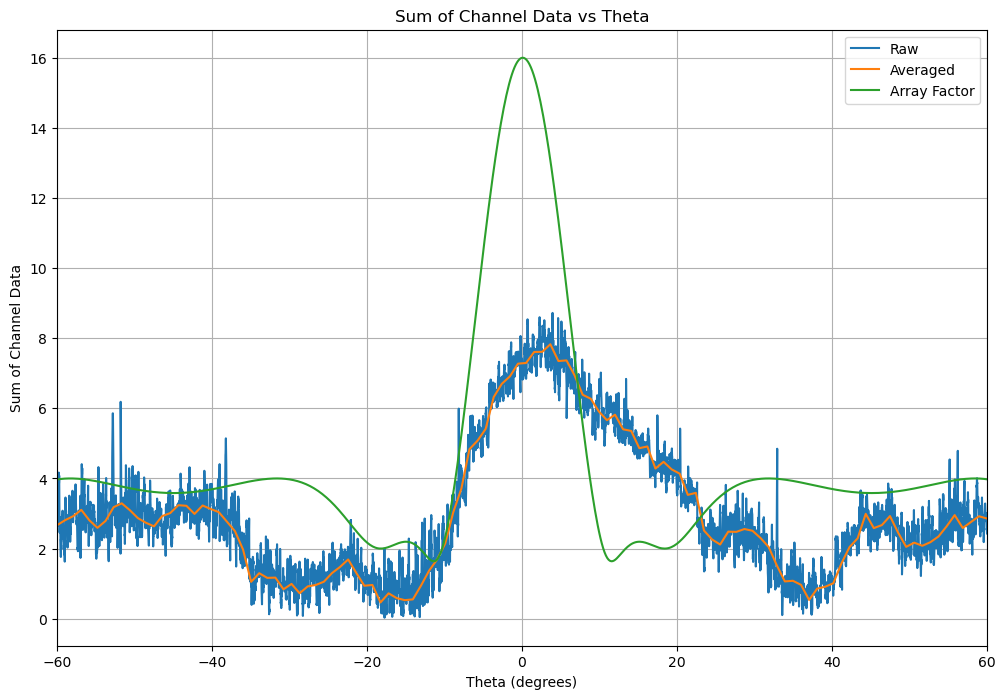

In [49]:
theta_range_avg = np.linspace(np.deg2rad(-60), np.deg2rad(60), len(channel_data_avg))
theta_range = np.linspace(np.deg2rad(-60), np.deg2rad(60), len(channel_data))

plt.figure(figsize=(12, 8))
plt.plot(np.rad2deg(theta_range), np.abs(np.sum(channel_data, axis=1)), label='Raw')
plt.plot(np.rad2deg(theta_range_avg), np.abs(np.sum(channel_data_avg, axis=1)), label='Averaged')
plt.plot(np.rad2deg(theta_vals), np.abs(af), label='Array Factor')
plt.grid()
plt.xlim(-60, 60)
plt.xlabel('Theta (degrees)')
plt.ylabel('Sum of Channel Data')
plt.title('Sum of Channel Data vs Theta')
plt.legend()
plt.show()

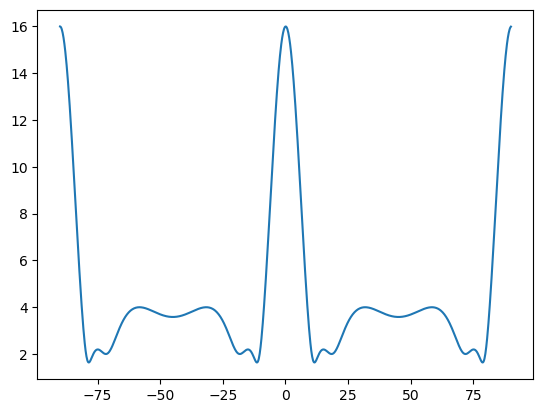

In [47]:
plt.figure()
plt.plot(np.rad2deg(theta_vals), np.abs(af))

<>:28: SyntaxWarning: invalid escape sequence '\p'
<>:28: SyntaxWarning: invalid escape sequence '\p'
C:\Users\Kanishka\AppData\Local\Temp\ipykernel_23388\677735356.py:28: SyntaxWarning: invalid escape sequence '\p'
  plt.title('Array Factor @ ($\\theta = 0, \phi = 0$) * Array Factor @ ($\\theta, \phi$) from all samples (each 100 samples are averaged)')


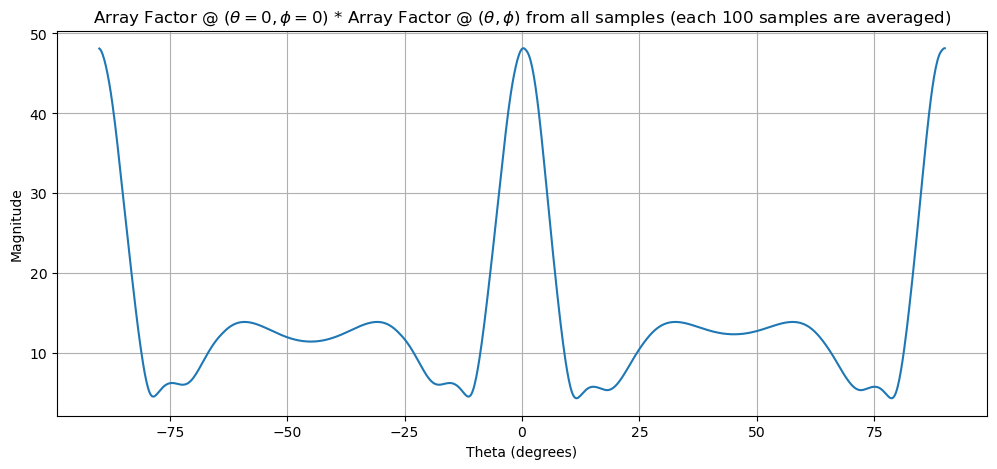

In [ ]:
spacing = 0.58 * session.frequency / 60.48
antenna_array = AntennaArray()
antenna_array_boresight = AntennaArray()
for ant in range(32):
    if ant not in valid_antennas:
        continue
    antenna_array.add_element(ordering_sets[ant, 0]*spacing - np.sign(ordering_sets[ant, 0])*spacing/2, 
            0, ordering_sets[ant, 1]*spacing - np.sign(ordering_sets[ant, 1])*spacing/2)
    antenna_array_boresight.add_element(ordering_sets[ant, 0]*spacing - np.sign(ordering_sets[ant, 0])*spacing/2, 
            0, ordering_sets[ant, 1]*spacing - np.sign(ordering_sets[ant, 1])*spacing/2)

antenna_array_boresight.set_weights(antenna_array_boresight.get_conjugate_beamformer(0, 0))
af, _, _ = antenna_array_boresight.get_array_pattern_azimuth(0, 1024, full=True)

theta_vals = np.linspace(-np.pi/2, np.pi/2, 1024)
result = np.zeros(len(theta_vals))

# for i in range(len(channel_data_avg)):
#     antenna_array.set_weights(np.conjugate(channel_data_avg[i, :]))
#     array_response, _, _ = antenna_array.get_array_pattern_azimuth(0, 1024, full=True)
#     result += np.abs(array_response * af)

plt.figure(figsize=(12, 5))
plt.plot(np.rad2deg(theta_vals), np.abs(result) / len(channel_data_avg))
plt.grid()
plt.xlabel('Theta (degrees)')
plt.ylabel('Magnitude')
plt.title('Array Factor @ ($\\theta = 0, \phi = 0$) * Array Factor @ ($\\theta, \phi$) from all samples (each 100 samples are averaged)')
plt.show()


<>:28: SyntaxWarning: invalid escape sequence '\p'
<>:28: SyntaxWarning: invalid escape sequence '\p'
C:\Users\Kanishka\AppData\Local\Temp\ipykernel_23388\3205440734.py:28: SyntaxWarning: invalid escape sequence '\p'
  plt.title('Array Factor @ ($\\theta = 0, \phi = 0$) * Array Factor @ ($\\theta, \phi$) from all samples')
100%|██████████| 9034/9034 [01:57<00:00, 76.70it/s]


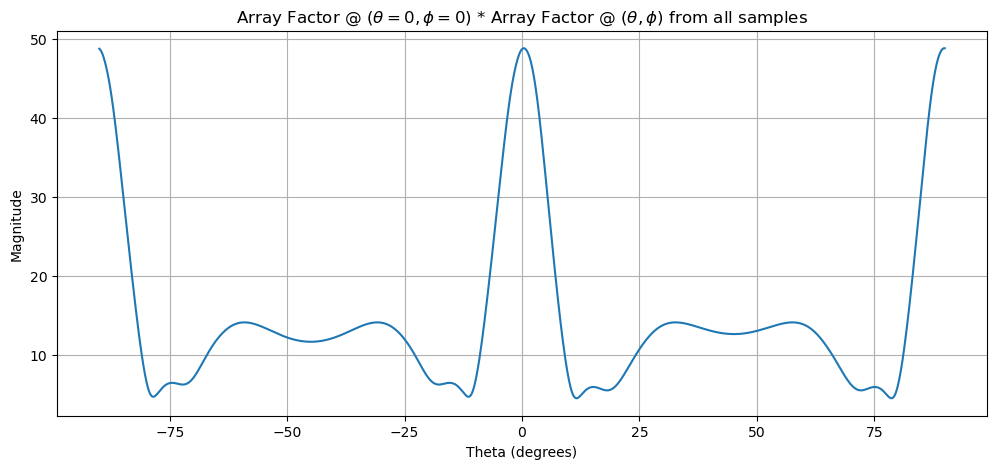

In [33]:
spacing = 0.58 * session.frequency / 60.48
antenna_array = AntennaArray()
antenna_array_boresight = AntennaArray()
for ant in range(32):
    if ant not in valid_antennas:
        continue
    antenna_array.add_element(ordering_sets[ant, 0]*spacing - np.sign(ordering_sets[ant, 0])*spacing/2, 
            0, ordering_sets[ant, 1]*spacing - np.sign(ordering_sets[ant, 1])*spacing/2)
    antenna_array_boresight.add_element(ordering_sets[ant, 0]*spacing - np.sign(ordering_sets[ant, 0])*spacing/2, 
            0, ordering_sets[ant, 1]*spacing - np.sign(ordering_sets[ant, 1])*spacing/2)

antenna_array_boresight.set_weights(antenna_array_boresight.get_conjugate_beamformer(0, 0))
af, _, _ = antenna_array_boresight.get_array_pattern_azimuth(0, 1024, full=True)

theta_vals = np.linspace(-np.pi/2, np.pi/2, 1024)
result = np.zeros(len(theta_vals))

for i in tqdm.trange(len(channel_data)):
    antenna_array.set_weights(np.conjugate(channel_data[i, :]))
    array_response, _, _ = antenna_array.get_array_pattern_azimuth(0, 1024, full=True)
    result += np.abs(array_response * af)

plt.figure(figsize=(12, 5))
plt.plot(np.rad2deg(theta_vals), np.abs(result) / len(channel_data))
plt.grid()
plt.xlabel('Theta (degrees)')
plt.ylabel('Magnitude')
plt.title('Array Factor @ ($\\theta = 0, \phi = 0$) * Array Factor @ ($\\theta, \phi$) from all samples')
plt.show()
